In [1]:
# === CELDA 0: INICIALIZACIÓN DEL NOTEBOOK DE ANÁLISIS EXPLORATORIO (RUN_AERMOD_EMISFACT) ===
import os
import glob
import urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8

# 1. Rutas fijas del proyecto apuntando directamente a run_aermod_emisfact
BASE = "/Users/gabrielevangelista/thesis-cdmx-air"
AERMAP_OUT = f"{BASE}/02-data/processed/aermap_out"
AERMET_OUT = f"{BASE}/02-data/processed/aermet_out"
RUN_DIR = f"{BASE}/03-analysis/run_aermod_emisfact"

FIG_OUT_DIR = f"{BASE}/03-analysis/education_outcomes/figuras_tesis"
os.makedirs(FIG_OUT_DIR, exist_ok=True)

CATALOGO_FUENTES_CSV = f"{AERMAP_OUT}/catalogo_285_fuentes_aermod_ap42.csv"
PLANEA_PANEL_CSV = f"{AERMAP_OUT}/planea_enlazado_receptores_2015_2019.csv"
TABLA_ENLACE_CSV = f"{AERMAP_OUT}/tabla_enlace_cct_recid.csv"

# 2. Capas vectoriales para mapas (Estados y Municipios de la ZMVM en UTM Zona 14N - km)
GEOJSON_STATES = f"{AERMAP_OUT}/mexico_estados.geojson"
GEOJSON_MUN = f"{AERMAP_OUT}/zmvm_municipios_inegi.geojson"

if not os.path.exists(GEOJSON_STATES):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/angelnmara/geojson/master/mexicoHigh.json", GEOJSON_STATES)

gdf_st = gpd.read_file(GEOJSON_STATES).to_crs("EPSG:32614")
gdf_st["geometry"] = gdf_st["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))
gdf_cdmx = gdf_st[gdf_st.geometry.centroid.x.between(470, 505) & gdf_st.geometry.centroid.y.between(2120, 2165)].copy()

gdf_mun = None
if os.path.exists(GEOJSON_MUN):
    gdf_mun = gpd.read_file(GEOJSON_MUN).to_crs("EPSG:32614")
    gdf_mun["geometry"] = gdf_mun["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))

# 3. Función lectora de archivos .plt de AERMOD
def leer_plt_aermod(filepath):
    records = []
    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("*"):
                continue
            p = s.split()
            if len(p) >= 5:
                try:
                    records.append({
                        "X_UTM": round(float(p[0]), 2),
                        "Y_UTM": round(float(p[1]), 2),
                        "CONC": float(p[2]),
                        "ZELEV": float(p[3]),
                        "ZHILL": float(p[4])
                    })
                except ValueError:
                    continue
    return pd.DataFrame(records)

plt_files = sorted(glob.glob(f"{RUN_DIR}/*.plt"))
print(f"[OK] RUN_DIR configurado en: {RUN_DIR}")
print(f"[OK] Total archivos .plt encontrados en run_aermod_emisfact: {len(plt_files)}")
for f in plt_files[:10]:
    print("   -", os.path.basename(f))


[OK] RUN_DIR configurado en: /Users/gabrielevangelista/thesis-cdmx-air/03-analysis/run_aermod_emisfact
[OK] Total archivos .plt encontrados en run_aermod_emisfact: 30
   - plot_emi_annual_all_2015.plt
   - plot_emi_annual_all_2016.plt
   - plot_emi_annual_all_2017.plt
   - plot_emi_annual_all_2018.plt
   - plot_emi_annual_all_2019.plt
   - plot_emi_annual_cald_2015.plt
   - plot_emi_annual_cald_2016.plt
   - plot_emi_annual_cald_2017.plt
   - plot_emi_annual_cald_2018.plt
   - plot_emi_annual_cald_2019.plt


In [2]:
# === CELDA 1: ASIMETRÍA DEL INVENTARIO POR RAMA TECNOLÓGICA (TABLA AP-42) ===
df_src = pd.read_csv(CATALOGO_FUENTES_CSV)

df_src["PM_KG_MEAN_15_17_19"] = df_src[["PM_KG_2015", "PM_KG_2017", "PM_KG_2019"]].mean(axis=1)
df_src["Q_GS_MEAN_15_17_19"] = df_src[["Q_GS_2015", "Q_GS_2017", "Q_GS_2019"]].mean(axis=1)

tab_ap42 = df_src.groupby("TECH_GROUP", as_index=False).agg(
    Plantas=("SRCID", "count"),
    Ratio_AP42=("RATIO_KG_PM_PER_T_CO2", "first"),
    Hs_m=("HS_M", "first"),
    Ts_K=("TS_K", "first"),
    Vs_ms=("VS_MS", "first"),
    Ds_m=("DS_M", "first"),
    Q_gs_total=("Q_GS_MEAN_15_17_19", "sum"),
    PM_ton_anual=("PM_KG_MEAN_15_17_19", lambda s: s.sum() / 1000.0)
)

tab_ap42["Pct_Padron"] = (tab_ap42["Plantas"] / tab_ap42["Plantas"].sum()) * 100.0
tab_ap42["Pct_Emision_PM25"] = (tab_ap42["Q_gs_total"] / tab_ap42["Q_gs_total"].sum()) * 100.0
tab_ap42 = tab_ap42.sort_values("Plantas", ascending=False).reset_index(drop=True)

display(tab_ap42[["TECH_GROUP", "Plantas", "Pct_Padron", "Ratio_AP42", "Hs_m", "Ts_K", "Pct_Emision_PM25"]].round(2))


,TECH_GROUP,Plantas,Pct_Padron,Ratio_AP42,Hs_m,Ts_K,Pct_Emision_PM25
0,CALDERA_IND,191,67.02,0.06,15.0,450.0,12.36
1,FUNDICION_METAL,47,16.49,0.65,22.0,370.0,23.53
2,SECADO_QUIM,19,6.67,0.25,25.0,365.0,3.25
3,TURBINA_GAS,17,5.96,0.06,30.0,750.0,40.99
4,HORNO_VIDRIO,9,3.16,0.45,45.0,550.0,17.05
5,MOTOR_RICE,2,0.70,0.13,12.0,673.0,2.83


In [3]:
# === CELDA 2: PANEL A - DESEMPEÑO ACADÉMICO Y CONTEXTO ESCOLAR (NIVEL CCT) ===
df_planea = pd.read_csv(PLANEA_PANEL_CSV)

# Puntaje continuo ponderado y estandarizado (Media = 500, DE = 100)
mat_raw = 1*df_planea["mat_pct_n1"] + 2*df_planea["mat_pct_n2"] + 3*df_planea["mat_pct_n3"] + 4*df_planea["mat_pct_n4"]
lyc_raw = 1*df_planea["lyc_pct_n1"] + 2*df_planea["lyc_pct_n2"] + 3*df_planea["lyc_pct_n3"] + 4*df_planea["lyc_pct_n4"]

df_planea["mat_std_500"] = 500.0 + 100.0 * (mat_raw - mat_raw.mean()) / mat_raw.std()
df_planea["lyc_std_500"] = 500.0 + 100.0 * (lyc_raw - lyc_raw.mean()) / lyc_raw.std()

# Indicadores de contexto (proporción 0 a 1 conforme a Mín=0.0 y Máx=1.0 de tu tabla)
df_planea["ind_marginacion_alta"] = df_planea["marginacion"].astype(str).str.upper().str.contains("ALTA|MUY ALTA", na=False).astype(float)
df_planea["ind_vespertino"] = (df_planea["turno"].astype(str).str.upper().str.strip() == "VESPERTINO").astype(float)

print(f"[OK] Observaciones CCT-turno-año en Panel A: {len(df_planea):,}")


[OK] Observaciones CCT-turno-año en Panel A: 12,096


In [4]:
# === CELDA 3: PANEL B - EXPOSICIÓN HIPERLOCAL CON EMISFACT (2015, 2017 Y 2019) ===
anios_panel = [2015, 2017, 2019]
grupos_plt = {
    "ALL": "all",
    "FUNDICION_METAL": "fund",
    "HORNO_VIDRIO": "vidr",
    "QUIMICA": "quim",
    "TURBINAS_CFE": "turb",
    "CALDERAS": "cald"
}

lista_anios_df = []
for yr in anios_panel:
    f_all = f"{RUN_DIR}/plot_emi_annual_all_{yr}.plt"
    df_yr = leer_plt_aermod(f_all).rename(columns={"CONC": "PM25_ALL"})
    df_yr["anio"] = yr
    
    for nombre_col, sufijo in grupos_plt.items():
        if nombre_col == "ALL":
            continue
        f_grp = f"{RUN_DIR}/plot_emi_annual_{sufijo}_{yr}.plt"
        if os.path.exists(f_grp):
            df_g = leer_plt_aermod(f_grp)[["X_UTM", "Y_UTM", "CONC"]].rename(columns={"CONC": f"PM25_{nombre_col}"})
            df_yr = df_yr.merge(df_g, on=["X_UTM", "Y_UTM"], how="left")
        else:
            df_yr[f"PM25_{nombre_col}"] = 0.0

    # Rama 6 (OTROS / MOTOR_RICE): si existe plot_annual_moto_YYYY.plt lo lee; si no, lo obtiene por diferencia exacta
    f_moto = f"{RUN_DIR}/plot_annual_moto_{yr}.plt"
    if os.path.exists(f_moto):
        df_m_plt = leer_plt_aermod(f_moto)[["X_UTM", "Y_UTM", "CONC"]].rename(columns={"CONC": "PM25_OTROS"})
        df_yr = df_yr.merge(df_m_plt, on=["X_UTM", "Y_UTM"], how="left")
    else:
        cols_5 = [f"PM25_{k}" for k in ["FUNDICION_METAL", "HORNO_VIDRIO", "QUIMICA", "TURBINAS_CFE", "CALDERAS"]]
        df_yr["PM25_OTROS"] = np.maximum(0.0, df_yr["PM25_ALL"] - df_yr[cols_5].sum(axis=1))
        
    lista_anios_df.append(df_yr)

df_aermod_panel = pd.concat(lista_anios_df, ignore_index=True)

# Cifras de diferencia a sotavento (para el párrafo 2 de tu texto)
df_zmvm_only = df_aermod_panel[df_aermod_panel["X_UTM"] >= 460000]
media_zmvm = df_zmvm_only["PM25_ALL"].mean()
q5_sotavento = df_zmvm_only[df_zmvm_only["PM25_ALL"] >= np.percentile(df_zmvm_only["PM25_ALL"], 80)]["PM25_ALL"].mean()
q1_barlovento = df_zmvm_only[df_zmvm_only["PM25_ALL"] <= np.percentile(df_zmvm_only["PM25_ALL"], 20)]["PM25_ALL"].mean()
p90_sotavento = np.percentile(df_zmvm_only["PM25_ALL"], 90)

print(f"[OK] Total observaciones Inmueble-Año (Panel B): {len(df_aermod_panel):,}")
print(f"-> Promedio metropolitano ZMVM (con EMISFACT): {media_zmvm:.4f} μg/m³")
print(f"-> Promedio en Quintil 5 (sotavento inmediato): {q5_sotavento:.4f} μg/m³ ({q5_sotavento/media_zmvm:.2f}x el promedio metropolitano y {q5_sotavento/q1_barlovento:.2f}x frente al Quintil 1)")
print(f"-> Umbral del Decil 10 (Top 10% más expuesto): >= {p90_sotavento:.4f} μg/m³")


[OK] Total observaciones Inmueble-Año (Panel B): 9,516
-> Promedio metropolitano ZMVM (con EMISFACT): 0.0696 μg/m³
-> Promedio en Quintil 5 (sotavento inmediato): 0.1601 μg/m³ (2.30x el promedio metropolitano y 7.89x frente al Quintil 1)
-> Umbral del Decil 10 (Top 10% más expuesto): >= 0.1326 μg/m³


In [5]:
# === CELDA 4: PANEL C (AERMET .SFC) E IMPRESIÓN DE TABLA LATEX COMPLETA ===
met_anual = []
for yr in anios_panel:
    sfc_file = f"{AERMET_OUT}/aer_{yr}.sfc"
    rows_sfc = []
    with open(sfc_file, "r") as f:
        for line in f.readlines()[1:]:
            p = line.split()
            if len(p) >= 22:
                rows_sfc.append({
                    "mo": int(p[1]), "dy": int(p[2]), "hr": int(p[4]),
                    "zic": float(p[9]), "ws": float(p[15]),
                    "temp_k": float(p[18]), "pamt": float(p[21])
                })
    df_sfc = pd.DataFrame(rows_sfc)
    df_sfc["ws_clean"] = df_sfc["ws"].replace([99.0, 999.0, -9.0], np.nan)
    df_sfc.loc[df_sfc["ws_clean"] > 50, "ws_clean"] = np.nan
    df_sfc["temp_c"] = df_sfc["temp_k"] - 273.15
    df_sfc.loc[(df_sfc["temp_k"] > 330) | (df_sfc["temp_k"] < 240), "temp_c"] = np.nan
    df_sfc["zic_clean"] = df_sfc["zic"].where((df_sfc["zic"] > 0) & (df_sfc["zic"] < 5000), np.nan)
    df_sfc["pamt_clean"] = df_sfc["pamt"].where((df_sfc["pamt"] >= 0) & (df_sfc["pamt"] < 200), 0.0)
    
    daily_t = df_sfc.groupby(["mo", "dy"])["temp_c"].agg(["max", "min"])
    met_anual.append({
        "anio": yr,
        "ws_mean": df_sfc["ws_clean"].mean(),
        "tmax_mean": daily_t["max"].mean(),
        "tmin_mean": daily_t["min"].mean(),
        "precip_sum": df_sfc["pamt_clean"].sum(),
        "zic_mean": df_sfc["zic_clean"].mean()
    })

df_met_yr = pd.DataFrame(met_anual)
df_panel_c = df_aermod_panel[["X_UTM", "Y_UTM", "anio"]].merge(df_met_yr, on="anio", how="left")
df_rec_unico = df_aermod_panel.drop_duplicates(subset=["X_UTM", "Y_UTM"])

def fmt_row(label, series, decimals=2):
    s = series.dropna()
    fmt = f"{{:.{decimals}f}}"
    return f"{label} & {fmt.format(s.mean())} & {fmt.format(s.std())} & {fmt.format(s.min())} & {fmt.format(s.max())} & {len(s):,} \\\\"

print("================ COPIAR DESDE AQUÍ PARA TU TABLA LATEX ================\n")
latex_rows = [
    r"\multicolumn{6}{l}{\textit{\textbf{Panel A: Desempeño Académico y Contexto Escolar (PLANEA, nivel CCT $i$)}}} \\",
    fmt_row("Puntaje promedio en Matemáticas (estandarizado)", df_planea["mat_std_500"], 1),
    fmt_row(r"Alumnos en Nivel I (Insuficiente - Matemáticas, \%)", df_planea["mat_pct_n1"], 2),
    fmt_row("Puntaje promedio en Lenguaje y Comunicación (estandarizado)", df_planea["lyc_std_500"], 1),
    fmt_row(r"Alumnos en Nivel I (Insuficiente - Lenguaje, \%)", df_planea["lyc_pct_n1"], 2),
    fmt_row(r"Indicador de Alta / Muy Alta Marginación (proporción)", df_planea["ind_marginacion_alta"], 3),
    fmt_row(r"Turno Vespertino (proporción)", df_planea["ind_vespertino"], 3) + "[0.15cm]",
    r"\multicolumn{6}{p{12cm}}{\textit{\textbf{Panel B: Exposición Hiperlocal a $\text{PM}_{2.5}$ Industrial (AERMOD a $1.5\text{ m}$, nivel Inmueble $r$)}}} \\",
    fmt_row(r"Concentración Total $\text{PM25\_AERMOD}_{rt}$ ($\mu\text{g/m}^3$, con \texttt{EMISFACT})", df_aermod_panel["PM25_ALL"], 4),
    fmt_row(r"\quad Rama 1: Fundición Metalúrgica (\texttt{FUNDICION\_METAL})", df_aermod_panel["PM25_FUNDICION_METAL"], 4),
    fmt_row(r"\quad Rama 2: Hornos de Vidrio y Minerales (\texttt{HORNO\_VIDRIO})", df_aermod_panel["PM25_HORNO_VIDRIO"], 4),
    fmt_row(r"\quad Rama 3: Industria Química y Petroquímica (\texttt{QUIMICA})", df_aermod_panel["PM25_QUIMICA"], 4),
    fmt_row(r"\quad Rama 4: Turbinas y Generación Eléctrica (\texttt{TURBINAS\_CFE})", df_aermod_panel["PM25_TURBINAS_CFE"], 4),
    fmt_row(r"\quad Rama 5: Calderas Industriales (\texttt{CALDERAS})", df_aermod_panel["PM25_CALDERAS"], 4),
    fmt_row(r"\quad Rama 6: Otras Fuentes de Combustión (\texttt{OTROS})", df_aermod_panel["PM25_OTROS"], 4),
    fmt_row(r"Elevación base del receptor escolar $Z_{\text{elev}, r}$ (m s.n.m., AERMAP)", df_rec_unico["ZELEV"], 1) + "[0.15cm]",
    r"\multicolumn{6}{l}{\textit{\textbf{Panel C: Variables Meteorológicas en Superficie (AERMET - Estación WMO 76679)}}} \\",
    fmt_row(r"Velocidad del viento en superficie ($v$, m/s)", df_panel_c["ws_mean"], 2),
    fmt_row(r"Temperatura máxima promedio ($^\circ\text{C}$)", df_panel_c["tmax_mean"], 2),
    fmt_row(r"Temperatura mínima promedio ($^\circ\text{C}$)", df_panel_c["tmin_mean"], 2),
    fmt_row(r"Precipitación acumulada (mm)", df_panel_c["precip_sum"], 1),
    fmt_row(r"Altura de capa de mezcla convectiva ($Z_{ic}$, m)", df_panel_c["zic_mean"], 1),
]
print("\n".join(latex_rows))


================ COPIAR DESDE AQUÍ PARA TU TABLA LATEX ================

\multicolumn{6}{l}{\textit{\textbf{Panel A: Desempeño Académico y Contexto Escolar (PLANEA, nivel CCT $i$)}}} \\
Puntaje promedio en Matemáticas (estandarizado) & 500.0 & 100.0 & 357.2 & 923.8 & 12,096 \\
Alumnos en Nivel I (Insuficiente - Matemáticas, \%) & 55.11 & 22.53 & 0.00 & 100.00 & 12,096 \\
Puntaje promedio en Lenguaje y Comunicación (estandarizado) & 500.0 & 100.0 & 254.1 & 876.9 & 12,094 \\
Alumnos en Nivel I (Insuficiente - Lenguaje, \%) & 27.07 & 17.29 & 0.00 & 100.00 & 12,094 \\
Indicador de Alta / Muy Alta Marginación (proporción) & 0.309 & 0.462 & 0.000 & 1.000 & 12,096 \\
Turno Vespertino (proporción) & 0.175 & 0.380 & 0.000 & 1.000 & 12,096 \\[0.15cm]
\multicolumn{6}{p{12cm}}{\textit{\textbf{Panel B: Exposición Hiperlocal a $\text{PM}_{2.5}$ Industrial (AERMOD a $1.5\text{ m}$, nivel Inmueble $r$)}}} \\
Concentración Total $\text{PM25\_AERMOD}_{rt}$ ($\mu\text{g/m}^3$, con \texttt{EMISFACT}) & 0.

In [6]:
# %% === CELDA 4c: TABLA 2.2 Y CIFRAS DE LA SECCIÓN 2.3, SOLO CUENCA DE MÉXICO ===
# Pegar en exploratorio_tesis_tablas DESPUÉS de la Celda 4.
# Usa: PLANEA_PANEL_CSV, df_aermod_panel, df_met_yr, fmt_row (definidos antes).
import numpy as np
import pandas as pd

X_MIN = 460000  # Cuenca de México: excluye el Valle de Toluca

# --- Panel A: PLANEA en la Cuenca, con turno armonizado (misma regla que la Celda 0b) ---
pl = pd.read_csv(PLANEA_PANEL_CSV)
pl["X_UTM"], pl["Y_UTM"] = pl["X_UTM"].round(2), pl["Y_UTM"].round(2)
pl = pl[pl["X_UTM"] >= X_MIN].copy()

MAPA_TURNO = {
    "1": "MATUTINO", "2": "VESPERTINO", "3": "NOCTURNO", "4": "DISCONTINUO", "5": "TIEMPO COMPLETO",
    "AMPLIADO": "TIEMPO COMPLETO", "COMPLETO": "TIEMPO COMPLETO",
    "JORNADA AMPLIAD": "TIEMPO COMPLETO", "JORNADA AMPLIADA": "TIEMPO COMPLETO",
    "CONTINUO": "TIEMPO COMPLETO", "CONTINUO (TIEMPO COMPLETO)": "TIEMPO COMPLETO",
}
pl["turno_norm"] = pl["turno"].astype(str).str.upper().str.strip().replace(MAPA_TURNO)
filas_max = pl.groupby(["cct", "anio"]).size().groupby("cct").max()
una_fila = pl["cct"].isin(filas_max[filas_max == 1].index)

def turno_modal(s):
    s_val = s[s != "DISCONTINUO"]
    return (s_val if len(s_val) else s).mode().iloc[0]

turno_cct = pl[una_fila].groupby("cct")["turno_norm"].agg(turno_modal)
pl["turno_arm"] = np.where(una_fila, pl["cct"].map(turno_cct), pl["turno_norm"])
pl["id_unidad"] = np.where(una_fila, pl["cct"].astype(str), pl["cct"].astype(str) + "_" + pl["turno_arm"].astype(str))

# Puntajes estandarizados dentro de la Cuenca (igual que en el notebook de regresiones)
mat_raw = sum(k * pl[f"mat_pct_n{k}"] for k in range(1, 5))
lyc_raw = sum(k * pl[f"lyc_pct_n{k}"] for k in range(1, 5))
pl["mat_std_500"] = 500 + 100 * (mat_raw - mat_raw.mean()) / mat_raw.std()
pl["lyc_std_500"] = 500 + 100 * (lyc_raw - lyc_raw.mean()) / lyc_raw.std()
pl["ind_marg"] = pl["marginacion"].astype(str).str.upper().str.contains("ALTA|MUY ALTA", na=False).astype(float)
pl["ind_vesp"] = (pl["turno_arm"] == "VESPERTINO").astype(float)

# --- Panel B: solo los receptores escolares de la Cuenca ---
rec_cuenca = pl[["X_UTM", "Y_UTM"]].drop_duplicates()
pb = df_aermod_panel.merge(rec_cuenca, on=["X_UTM", "Y_UTM"], how="inner")
pc = pb[["X_UTM", "Y_UTM", "anio"]].merge(df_met_yr, on="anio", how="left")
rec_u = pb.drop_duplicates(subset=["X_UTM", "Y_UTM"])

filas = [
    r"\multicolumn{6}{l}{\textit{\textbf{Panel A: Desempe\~no acad\'emico y contexto escolar (PLANEA, nivel CCT $i$)}}} \\",
    fmt_row(r"Puntaje en Matem\'aticas (estandarizado)", pl["mat_std_500"], 1),
    fmt_row(r"Alumnos en Nivel I, Matem\'aticas (\%)", pl["mat_pct_n1"], 2),
    fmt_row(r"Puntaje en Lenguaje y Comunicaci\'on (estandarizado)", pl["lyc_std_500"], 1),
    fmt_row(r"Alumnos en Nivel I, Lenguaje (\%)", pl["lyc_pct_n1"], 2),
    fmt_row(r"Alta o muy alta marginaci\'on (proporci\'on)", pl["ind_marg"], 3),
    fmt_row(r"Turno vespertino (proporci\'on)", pl["ind_vesp"], 3) + "[0.15cm]",
    r"\multicolumn{6}{p{12cm}}{\textit{\textbf{Panel B: Exposici\'on a $\text{PM}_{2.5}$ industrial (AERMOD a $1.5\text{ m}$, nivel inmueble $r$)}}} \\",
    fmt_row(r"Concentraci\'on total $\text{PM25\_AERMOD}_{rt}$ ($\mu\text{g/m}^3$)", pb["PM25_ALL"], 4),
    fmt_row(r"\quad Fundici\'on y metalurgia", pb["PM25_FUNDICION_METAL"], 4),
    fmt_row(r"\quad Hornos de vidrio y minerales", pb["PM25_HORNO_VIDRIO"], 4),
    fmt_row(r"\quad Secado qu\'imico", pb["PM25_QUIMICA"], 4),
    fmt_row(r"\quad Turbinas de gas", pb["PM25_TURBINAS_CFE"], 4),
    fmt_row(r"\quad Calderas industriales", pb["PM25_CALDERAS"], 4),
    fmt_row(r"\quad Motores estacionarios y residuo", pb["PM25_OTROS"], 4),
    fmt_row(r"Elevaci\'on del receptor $Z_{\text{elev},r}$ (m s.n.m.)", rec_u["ZELEV"], 1) + "[0.15cm]",
    r"\multicolumn{6}{l}{\textit{\textbf{Panel C: Variables meteorol\'ogicas en superficie (AERMET, estaci\'on WMO 76679)}}} \\",
    fmt_row(r"Velocidad del viento (m/s)", pc["ws_mean"], 2),
    fmt_row(r"Temperatura m\'axima promedio ($^\circ\text{C}$)", pc["tmax_mean"], 2),
    fmt_row(r"Temperatura m\'inima promedio ($^\circ\text{C}$)", pc["tmin_mean"], 2),
    fmt_row(r"Precipitaci\'on acumulada (mm)", pc["precip_sum"], 1),
    fmt_row(r"Altura de la capa de mezcla convectiva ($Z_{ic}$, m)", pc["zic_mean"], 1),
]
print("================ FILAS PARA LA TABLA 2.2 (CUENCA DE MÉXICO) ================\n")
print("\n".join(filas))

print("\n================ CIFRAS PARA EL TEXTO DE LA SECCIÓN 2.3 ================")
print(f"Observaciones: {len(pl):,} | CCT: {pl['cct'].nunique():,} | unidades: {pl['id_unidad'].nunique():,} "
      f"| inmuebles: {pl['RECID'].nunique():,} | inmueble-año en Panel B: {len(pb):,}")
total = pb["PM25_ALL"].mean()
for col, lab in [("PM25_FUNDICION_METAL", "Fundición"), ("PM25_TURBINAS_CFE", "Turbinas"),
                 ("PM25_CALDERAS", "Calderas"), ("PM25_HORNO_VIDRIO", "Vidrio"), ("PM25_QUIMICA", "Secado químico")]:
    print(f"{lab:15s}: media {pb[col].mean():.4f} µg/m³ ({100 * pb[col].mean() / total:.1f}% del total), máximo {pb[col].max():.4f}")
print(f"Media total en la Cuenca: {total:.4f} µg/m³")

================ FILAS PARA LA TABLA 2.2 (CUENCA DE MÉXICO) ================

\multicolumn{6}{l}{\textit{\textbf{Panel A: Desempe\~no acad\'emico y contexto escolar (PLANEA, nivel CCT $i$)}}} \\
Puntaje en Matem\'aticas (estandarizado) & 500.0 & 100.0 & 355.2 & 915.9 & 9,459 \\
Alumnos en Nivel I, Matem\'aticas (\%) & 54.48 & 22.65 & 0.00 & 100.00 & 9,459 \\
Puntaje en Lenguaje y Comunicaci\'on (estandarizado) & 500.0 & 100.0 & 248.0 & 862.0 & 9,457 \\
Alumnos en Nivel I, Lenguaje (\%) & 25.67 & 16.99 & 0.00 & 100.00 & 9,457 \\
Alta o muy alta marginaci\'on (proporci\'on) & 0.233 & 0.423 & 0.000 & 1.000 & 9,459 \\
Turno vespertino (proporci\'on) & 0.230 & 0.421 & 0.000 & 1.000 & 9,459 \\[0.15cm]
\multicolumn{6}{p{12cm}}{\textit{\textbf{Panel B: Exposici\'on a $\text{PM}_{2.5}$ industrial (AERMOD a $1.5\text{ m}$, nivel inmueble $r$)}}} \\
Concentraci\'on total $\text{PM25\_AERMOD}_{rt}$ ($\mu\text{g/m}^3$) & 0.0696 & 0.0761 & 0.0046 & 2.5166 & 7,176 \\
\quad Fundici\'on y metalurgia & 

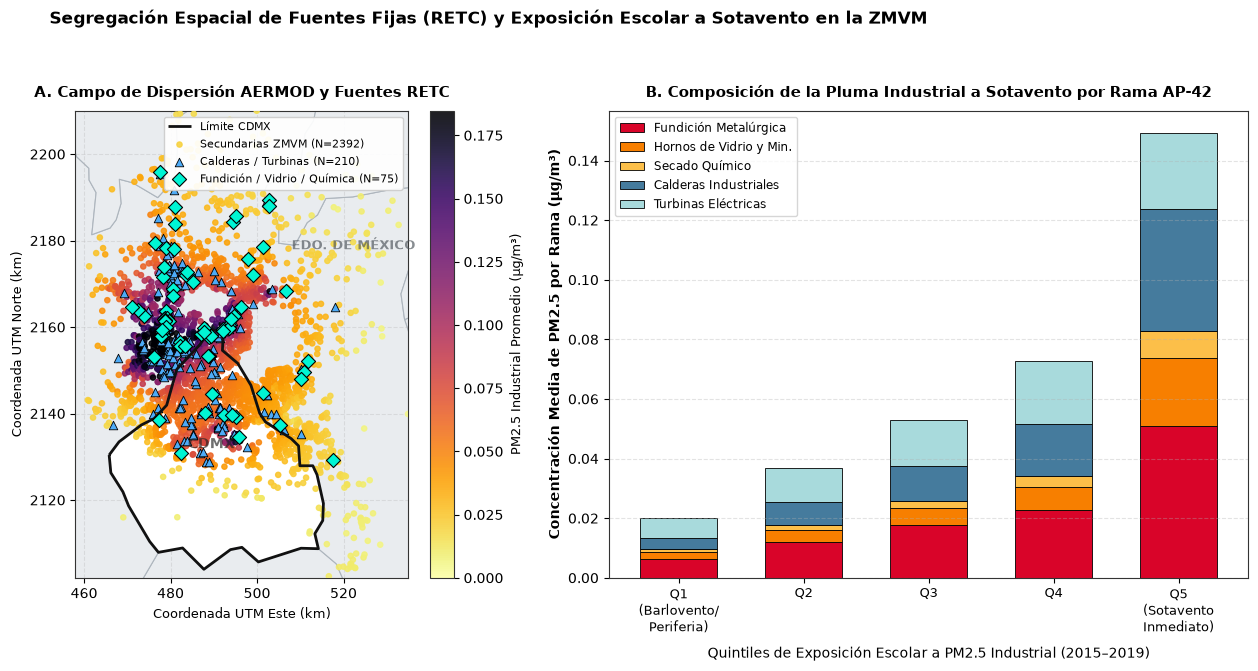

[OK] Figura guardada en: /Users/gabrielevangelista/thesis-cdmx-air/03-analysis/education_outcomes/figuras_tesis/fig_exploratorio_plumas_ramas_tesis.png


In [7]:
# === CELDA 5: FIGURA EXPLORATORIA DE PLUMAS AERMOD (EMISFACT) Y DESCOMPOSICIÓN POR RAMA ===
df_map_mean = df_aermod_panel[df_aermod_panel["X_UTM"] >= 460000].groupby(["X_UTM", "Y_UTM"], as_index=False).agg(
    PM25_ALL=("PM25_ALL", "mean"),
    PM25_FUND=("PM25_FUNDICION_METAL", "mean"),
    PM25_VIDR=("PM25_HORNO_VIDRIO", "mean"),
    PM25_QUIM=("PM25_QUIMICA", "mean"),
    PM25_CALD=("PM25_CALDERAS", "mean"),
    PM25_TURB=("PM25_TURBINAS_CFE", "mean")
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1.15, 1]})

# Panel A: Mapa de Pluma Promedio (EMISFACT) y Fuentes por Intensidad
ax1.set_facecolor("#f2f4f7")
gdf_st.plot(ax=ax1, facecolor="#e9ecef", edgecolor="#adb5bd", linewidth=0.8, zorder=1)
if gdf_mun is not None:
    gdf_mun.plot(ax=ax1, facecolor="none", edgecolor="#ced4da", linewidth=0.45, zorder=2)
if len(gdf_cdmx) > 0:
    gdf_cdmx.plot(ax=ax1, facecolor="#ffffff", edgecolor="none", zorder=2)
    gdf_cdmx.boundary.plot(ax=ax1, edgecolor="#111111", linewidth=2.0, zorder=5, label="Límite CDMX")

vmax = np.percentile(df_map_mean["PM25_ALL"], 96)
sc = ax1.scatter(
    df_map_mean["X_UTM"] / 1000.0, df_map_mean["Y_UTM"] / 1000.0,
    c=df_map_mean["PM25_ALL"], cmap="inferno_r", s=14, alpha=0.88,
    vmin=0, vmax=vmax, zorder=3, label=f"Secundarias ZMVM (N={len(df_map_mean)})"
)

src_pesadas = df_src[df_src["TECH_GROUP"].isin(["FUNDICION_METAL", "HORNO_VIDRIO", "SECADO_QUIM"])]
src_otras = df_src[~df_src["TECH_GROUP"].isin(["FUNDICION_METAL", "HORNO_VIDRIO", "SECADO_QUIM"])]

ax1.scatter(src_otras["X_UTM"]/1000.0, src_otras["Y_UTM"]/1000.0, marker="^", c="#4dabf7", edgecolors="black", s=38, linewidths=0.6, zorder=4, label=f"Calderas / Turbinas (N={len(src_otras)})")
ax1.scatter(src_pesadas["X_UTM"]/1000.0, src_pesadas["Y_UTM"]/1000.0, marker="D", c="#00f5d4", edgecolors="black", s=52, linewidths=0.8, zorder=6, label=f"Fundición / Vidrio / Química (N={len(src_pesadas)})")

ax1.text(484, 2132, "CDMX", fontsize=10, fontweight="bold", color="#222222", alpha=0.65, zorder=6)
ax1.text(508, 2178, "EDO. DE MÉXICO", fontsize=9.5, fontweight="bold", color="#495057", alpha=0.65, zorder=6)

ax1.set_xlim(458, 535)
ax1.set_ylim(2102, 2210)
cbar = plt.colorbar(sc, ax=ax1, fraction=0.046, pad=0.03)
cbar.set_label("PM2.5 Industrial Promedio (μg/m³)", fontsize=9.5)
ax1.set_title("A. Campo de Dispersión AERMOD y Fuentes RETC", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("Coordenada UTM Este (km)", fontsize=9.5)
ax1.set_ylabel("Coordenada UTM Norte (km)", fontsize=9.5)
ax1.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.92, fontsize=8.2)
ax1.grid(True, linestyle="--", alpha=0.3, zorder=0)

# Panel B: Contribución por Rama Tecnológica según Quintil de Exposición Total
df_map_mean["quintil"] = pd.qcut(df_map_mean["PM25_ALL"], q=5, labels=["Q1\n(Barlovento/\nPeriferia)", "Q2", "Q3", "Q4", "Q5\n(Sotavento\nInmediato)"])
q_ramas = df_map_mean.groupby("quintil", observed=False)[["PM25_FUND", "PM25_VIDR", "PM25_QUIM", "PM25_CALD", "PM25_TURB"]].mean()

q_ramas.plot(
    kind="bar", stacked=True, ax=ax2, width=0.62, edgecolor="black", linewidth=0.6,
    color=["#d90429", "#f77f00", "#fcbf49", "#457b9d", "#a8dadc"]
)
ax2.set_xticklabels(q_ramas.index, rotation=0, fontsize=9)
ax2.set_xlabel("Quintiles de Exposición Escolar a PM2.5 Industrial (2015–2019)", fontsize=10, labelpad=8)
ax2.set_ylabel("Concentración Media de PM2.5 por Rama (μg/m³)", fontsize=10, fontweight="bold")
ax2.set_title("B. Composición de la Pluma Industrial a Sotavento por Rama AP-42", fontsize=11, fontweight="bold", pad=10)
ax2.legend(["Fundición Metalúrgica", "Hornos de Vidrio y Min.", "Secado Químico", "Calderas Industriales", "Turbinas Eléctricas"], loc="upper left", frameon=True, facecolor="white", fontsize=8.8)
ax2.grid(True, axis="y", linestyle="--", alpha=0.35)

plt.suptitle("Segregación Espacial de Fuentes Fijas (RETC) y Exposición Escolar a Sotavento en la ZMVM", fontsize=12.5, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
out_exp_fig = f"{FIG_OUT_DIR}/fig_exploratorio_plumas_ramas_tesis.png"
plt.savefig(out_exp_fig, dpi=300)
plt.show()
print(f"[OK] Figura guardada en: {out_exp_fig}")


In [8]:
# === VERIFICACIÓN DE CONTEO EXACTO: CCT, TURNOS Y RECID ===
df_enlace = pd.read_csv(TABLA_ENLACE_CSV)
df_planea = pd.read_csv(PLANEA_PANEL_CSV)

print("--- 1. EN TABLA PUENTE (tabla_enlace_cct_recid.csv) ---")
print(f"Filas totales: {len(df_enlace):,}")
print(f"CCT únicas: {df_enlace['cct'].nunique():,}")
print(f"Pares únicos (CCT + turno): {len(df_enlace.drop_duplicates(subset=['cct', 'turno'])):,}")
print(f"Inmuebles / RECID únicos: {df_enlace['RECID'].nunique():,}")

print("\n--- 2. EN PANEL PLANEA ENLAZADO (planea_enlazado_receptores_2015_2019.csv) ---")
print(f"Filas totales (observaciones): {len(df_planea):,}")
print(f"CCT únicas en el panel: {df_planea['cct'].nunique():,}")
print(f"Pares únicos (CCT + turno) en el panel: {len(df_planea.drop_duplicates(subset=['cct', 'turno'])):,}")
print(f"Inmuebles / RECID únicos en el panel: {df_planea['RECID'].nunique():,}")

print("\nDesglose por año en el panel:")
print(df_planea.groupby("anio").agg(
    observaciones=("cct", "count"),
    ccts_unicas=("cct", "nunique"),
    recids_unicos=("RECID", "nunique")
))

# Verificar si hay duplicados de (cct, turno, anio)
dups = df_planea.duplicated(subset=["cct", "turno", "anio"]).sum()
print(f"\nRegistros duplicados por (cct, turno, anio): {dups}")


--- 1. EN TABLA PUENTE (tabla_enlace_cct_recid.csv) ---
Filas totales: 3,833
CCT únicas: 3,833
Pares únicos (CCT + turno): 3,833
Inmuebles / RECID únicos: 3,172

--- 2. EN PANEL PLANEA ENLAZADO (planea_enlazado_receptores_2015_2019.csv) ---
Filas totales (observaciones): 12,096
CCT únicas en el panel: 3,833
Pares únicos (CCT + turno) en el panel: 5,776
Inmuebles / RECID únicos en el panel: 3,172

Desglose por año en el panel:
      observaciones  ccts_unicas  recids_unicos
anio                                           
2015           4040         3833           3172
2017           4030         3833           3172
2019           4026         3833           3172

Registros duplicados por (cct, turno, anio): 0
